Question 68. Train a Random Forest classifier for Purchase and plot feature importances.

Original dataset:


,ID,Age,Income,Spending Score,Region,Category,Visits,Online Time,Purchase,Rating
0,1,22,25000,65,North,Grocery,5,12,Yes,4.2
1,2,35,55000,40,West,Electronics,2,8,No,3.8
2,3,28,32000,70,South,Clothing,6,15,Yes,4.5
3,4,45,75000,30,East,Grocery,3,6,No,3.5
4,5,30,60000,80,South,Electronics,7,18,Yes,4.8
5,6,26,40000,55,North,Clothing,4,10,Yes,4.1
6,7,38,50000,45,West,Grocery,3,9,No,3.9
7,8,29,45000,75,South,Electronics,6,16,Yes,4.6
8,9,50,80000,35,West,Clothing,2,5,No,3.6
9,10,33,52000,60,North,Grocery,5,11,Yes,4.3


Test accuracy: 1.000


numeric__Spending Score              0.178231
numeric__Income                      0.168474
numeric__Age                         0.167730
numeric__Online Time                 0.167234
numeric__Visits                      0.154507
categorical__Region_North            0.069196
categorical__Region_West             0.051658
categorical__Region_East             0.015306
categorical__Category_Grocery        0.014853
categorical__Category_Clothing       0.006293
categorical__Category_Electronics    0.004252
categorical__Region_South            0.002268
dtype: float64

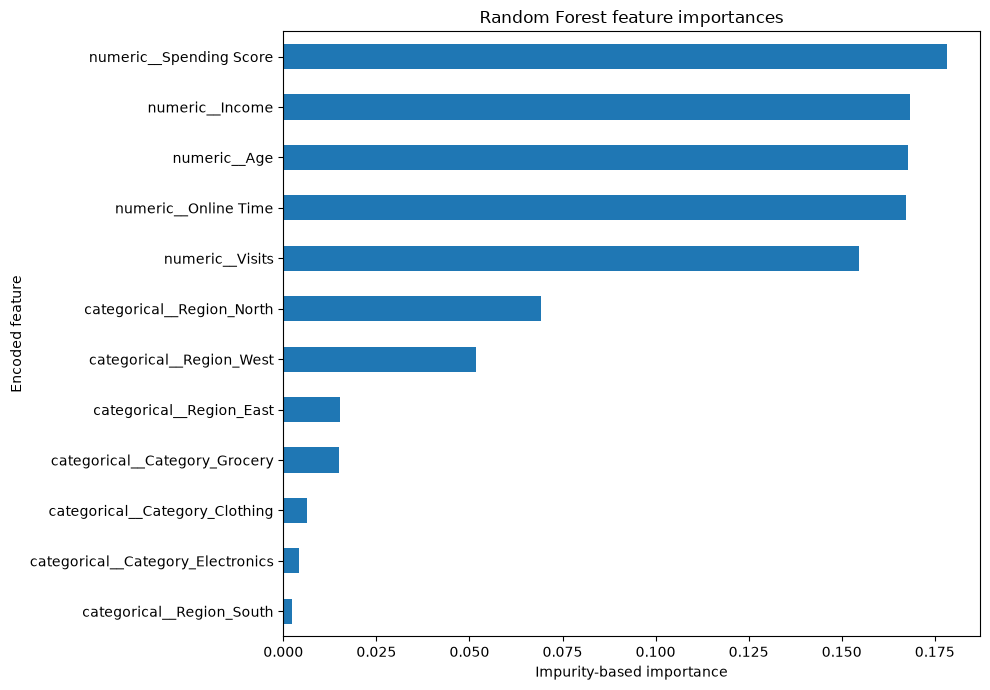

Saved question68_plot.png


In [1]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_PurchaseData.csv")
print("Original dataset:")
display(df)

# Step 3: Select predictors and the purchase outcome; exclude ID and Rating.
X = df.drop(columns=["ID", "Purchase", "Rating"])
y = df["Purchase"]

# Step 4: Identify numeric and categorical columns.
numeric = ["Age", "Income", "Spending Score", "Visits", "Online Time"]
categorical = ["Region", "Category"]

# Step 5: Make a fixed stratified train/test split.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Step 6: Define training-only categorical encoding.
preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])



# Step 7: Combine preprocessing with a forest of 200 decision trees.
model = Pipeline([("preprocess", preprocessor),
                  ("classifier", RandomForestClassifier(n_estimators=200, random_state=42))])

# Step 8: Fit the forest and report held-out test accuracy.
model.fit(X_train, y_train)
print(f"Test accuracy: {model.score(X_test, y_test):.3f}")

# Step 9: Read and sort feature importance values from the trained forest.
importance = pd.Series(model.named_steps["classifier"].feature_importances_,
                       index=model.named_steps["preprocess"].get_feature_names_out())
importance = importance.sort_values()

# Step 10: Plot feature importances and save the numeric values.
fig, ax = plt.subplots(figsize=(10, 7))
importance.plot.barh(ax=ax)
ax.set(xlabel="Impurity-based importance", ylabel="Encoded feature",
       title="Random Forest feature importances")
importance.rename("Importance").to_csv("feature_importances.csv")
display(importance.sort_values(ascending=False))

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question68_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question68_plot.png")


Interpretation / method

ID is an identifier and is excluded. Rating is also excluded because it may only be known after a purchase; this avoids potential target leakage. Categorical encoding is fitted only on the training data. The fixed, stratified split has seven training and three test rows; accuracy on three rows is only an illustration, not reliable evidence of generalisation. Impurity importances can be unstable and biased on tiny samples; they are not causal effects.